# Домашнее задание

## Задание 2. MDE по данным

### Загрузка данных


In [2]:
from typing import Iterable, Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest, chisquare, norm, ttest_ind

users = pd.read_csv("users.csv", parse_dates=["reg_date"])
user_week_metrics = pd.read_csv("user_week_metrics.csv", parse_dates=["week_start"])

target = "relevant_responses_app"
guardrail = "invitations_app"

print(f"Пользователей в справочнике: {len(users)}")
print(f"Строк в недельной таблице: {len(user_week_metrics)}")

Пользователей в справочнике: 388000
Строк в недельной таблице: 870685


### Качество данных

In [3]:
def summarize_dq(df: pd.DataFrame, key_cols: Optional[Iterable[str]] = None) -> pd.DataFrame:
    rows = [
        {"проверка": "строк всего", "значение": len(df)},
        {"проверка": "полных дублей строк", "значение": int(df.duplicated().sum())},
    ]
    for c in df.columns:
        rows.append({"проверка": f"пропуски: {c}", "значение": int(df[c].isna().sum())})
    if key_cols:
        key_cols = list(key_cols)
        rows.append({"проверка": f"дубли по ключу: {'+'.join(key_cols)}",
                     "значение": int(df.duplicated(key_cols).sum())})
    return pd.DataFrame(rows)

print("структура users:")
display(users.dtypes.rename("тип данных").to_frame())
print("структура user_week_metrics:")
display(user_week_metrics.dtypes.rename("тип данных").to_frame())

print("проверки users:")
display(summarize_dq(users, ["user_id"]))
print("проверки user_week_metrics:")
display(summarize_dq(user_week_metrics, ["user_id", "week_start"]))

структура users:


,тип данных
user_id,int64
user_type,str
reg_date,datetime64[us]
region_group,str
platform,str
company_size,str


структура user_week_metrics:


,тип данных
week_start,datetime64[us]
user_id,int64
user_type,str
vacancy_views_app,float64
responses_app,float64
relevant_responses_app,float64
invitations_app,float64
responses_emp,float64
relevant_responses_emp,float64
invitations_emp,float64


проверки users:


,проверка,значение
0,строк всего,388000
1,полных дублей строк,0
2,пропуски: user_id,0
3,пропуски: user_type,0
4,пропуски: reg_date,0
5,пропуски: region_group,8000
6,пропуски: platform,8000
7,пропуски: company_size,380000
8,дубли по ключу: user_id,0


проверки user_week_metrics:


,проверка,значение
0,строк всего,870685
1,полных дублей строк,0
2,пропуски: week_start,0
3,пропуски: user_id,0
4,пропуски: user_type,0
5,пропуски: vacancy_views_app,47147
6,пропуски: responses_app,47147
7,пропуски: relevant_responses_app,47147
8,пропуски: invitations_app,47147
9,пропуски: responses_emp,823538


В справочнике 388000 пользователей, user_id уникален. В недельной таблице 870685 строк, полных дублей и повторов ключей нет. В полях каждой метрики соискателя по 47147 пропусков. Пропуски в users объяснимы типом пользователя: region_group и platform не заполнены у 8000 работодателей, а company_size у 380000 соискателей. В недельных показателях пусты поля метрик другой аудитории: у соискателя заполнены _app, у работодателя _emp. Факт этих пропусков не означает потерю данных.


#### Связь таблиц, календарь и воронка

In [4]:
app_cols = ["vacancy_views_app", "responses_app", target, guardrail]
emp_cols = ["responses_emp", "relevant_responses_emp", "invitations_emp"]
applicants = user_week_metrics.loc[user_week_metrics["user_type"].eq("APPLICANT")].copy()
employers = user_week_metrics.loc[user_week_metrics["user_type"].eq("EMPLOYER")]
profiles = user_week_metrics[["user_id", "user_type", "week_start"]].merge(
    users[["user_id", "user_type", "reg_date"]], on="user_id", how="left",
    suffixes=("_week", "_profile"), validate="many_to_one", indicator=True,
)

def funnel_errors(frame, responses, relevant, invites):
    return int(((frame[invites] > frame[relevant]) | (frame[relevant] > frame[responses])).sum())

counts = user_week_metrics[app_cols + emp_cols]
expected_weeks = pd.date_range("2026-03-09", "2026-05-04", freq="W-MON")
observed_weeks = pd.DatetimeIndex(user_week_metrics["week_start"].dropna().unique())
checks = pd.Series({
    "Пустые ключи справочника": users["user_id"].isna().sum(),
    "Пустые ключи недельной таблицы": user_week_metrics[["user_id", "week_start"]].isna().any(axis=1).sum(),
    "Повторы недельного ключа": user_week_metrics.duplicated(["user_id", "week_start"]).sum(),
    "Неизвестный тип в недельной таблице": (~user_week_metrics["user_type"].isin(["APPLICANT", "EMPLOYER"])).sum(),
    "Строки без профиля": profiles["_merge"].eq("left_only").sum(),
    "Несовпадения типа пользователя": profiles["user_type_week"].ne(profiles["user_type_profile"]).sum(),
    "Активность до недели регистрации": (profiles["reg_date"] > profiles["week_start"] + pd.Timedelta(days=6)).sum(),
    "Отклонения от календаря (даты недель)": len(expected_weeks.symmetric_difference(observed_weeks)),
    "Пустые app-поля у соискателей": applicants[app_cols].isna().sum().sum(),
    "Пустые emp-поля у работодателей": employers[emp_cols].isna().sum().sum(),
    "Заполненные поля чужой роли": applicants[emp_cols].notna().sum().sum() + employers[app_cols].notna().sum().sum(),
    "Отрицательные счетчики": (counts < 0).sum().sum(),
    "Не целые или бесконечные счетчики": (counts.notna() & counts.mod(1).ne(0)).sum().sum(),
    "Нарушения воронки соискателей": funnel_errors(applicants, "responses_app", target, guardrail),
    "Нарушения воронки работодателей": funnel_errors(employers, *emp_cols),
}, name="Количество нарушений")

display(checks.to_frame())

,Количество нарушений
Пустые ключи справочника,0
Пустые ключи недельной таблицы,0
Повторы недельного ключа,0
Неизвестный тип в недельной таблице,0
Строки без профиля,0
Несовпадения типа пользователя,0
Активность до недели регистрации,0
Отклонения от календаря (даты недель),0
Пустые app-поля у соискателей,0
Пустые emp-поля у работодателей,0


Все проверки дали ноль нарушений.

### Выбор исторического окна

Сравниваем недельную аудиторию и средние метрики по всем девяти неделям. Для прогноза используем окна длительностью от одной до пяти полных недель с общей датой старта.

In [5]:
history = applicants.groupby("week_start").agg(
    active_users=("user_id", "nunique"),
    responding_users=("responses_app", lambda counts: counts.gt(0).sum()),
    relevant_per_user=(target, "mean"),
    invitations_per_user=(guardrail, "mean"),
)
display(history.round(4))


,active_users,responding_users,relevant_per_user,invitations_per_user
week_start,,,,
2026-03-09,102701,94675,2.6906,0.3304
2026-03-16,103872,95857,2.6699,0.3288
2026-03-23,103090,95082,2.7017,0.3320
2026-03-30,101859,93844,2.6951,0.3310
2026-04-06,102791,94868,2.6916,0.3315
2026-04-13,103926,95994,2.7233,0.3326
2026-04-20,102599,94635,2.6810,0.3287
2026-04-27,53178,34259,2.6672,0.3376
2026-05-04,49522,31660,2.5760,0.3224


Исторический аналог теста: с 6 апреля по 10 мая 2026 года. При старте 5 апреля 2027 года майские праздники тоже приходятся на четвертую и пятую недели. Общая дата старта позволяет сравнить три недели до праздников.

В первые семь недель всей истории активны примерно 102–104 тысячи соискателей в неделю. С 27 апреля их число снизилось до 53178, с 4 мая до 49522. При этом на неделе 27 апреля у активного соискателя в среднем 2,67 релевантного отклика против 2,68 неделей ранее. Наиболее заметным изменением в этот момент является падение недельной аудитории.

### Популяция и метрики на пользователя

В эксперименте закрепляем группу за user_id при сплите 50/50. В анализ входят соискатели, которые за время теста отправили хотя бы один успешный отклик. Первый такой отклик - trigger event. Событие фиксируется одинаково в обеих группах до показа экрана после отклика.

Целевая метрика - число релевантных откликов (relevant_responses_app). Отклик считается релевантным, если работодатель пригласил соискателя или посмотрел его контакты.
Guardrail - число приглашений (invitations_app).

### Расчет MDE для окон от одной до пяти недель

Используем нормальное приближение при $\alpha=0{,}05$ и мощности 80%. При $n=N/2$ соискателях на группу стандартная ошибка разницы средних равна $s\sqrt{2/n}$. Абсолютный MDE равен $(z_\mathrm{crit}+z_{0{,}80})\cdot s\sqrt{2/n}$, относительный равен абсолютному MDE в процентах от исторического среднего.
Для целевой метрики используем двусторонний квантиль $z_{0{,}975}$, для обнаружения снижения приглашений относительно нулевого эффекта используем односторонний $z_{0{,}95}$. Бизнес-порог 3% используем при выборе длительности.

In [6]:
history_start = pd.Timestamp("2026-04-06")
alpha = 0.05
power = 0.80
target_limit_pct = 1.7
guardrail_limit_pct = 3.0
z_power = norm.ppf(power)
z_critical = {target: norm.ppf(1 - alpha / 2), guardrail: norm.ppf(1 - alpha)}


def mde_rows(user_totals, weeks):
    total_users = len(user_totals)
    group_size = total_users / 2
    rows = []
    for metric, z_alpha in z_critical.items():
        values = user_totals[metric]
        mean = values.mean()
        std = values.std(ddof=1)
        standard_error = std * np.sqrt(2 / group_size)
        mde_abs = (z_alpha + z_power) * standard_error
        rows.append({
            "weeks": weeks, "metric": metric, "users": total_users,
            "mean": mean, "std": std, "cv": std / mean,
            "mde_abs": mde_abs, "mde_pct": 100 * mde_abs / mean,
        })
    return rows


triggered_by_weeks = {}
rows = []
for weeks in range(1, 6):
    end = history_start + pd.Timedelta(weeks=weeks)
    in_window = applicants["week_start"].ge(history_start) & applicants["week_start"].lt(end)
    user_totals = (
        applicants.loc[in_window]
        .groupby("user_id")[[target, guardrail, "responses_app"]]
        .sum()
    )
    triggered_totals = user_totals.loc[user_totals["responses_app"].gt(0)]
    triggered_by_weeks[weeks] = triggered_totals
    rows.extend(mde_rows(triggered_totals, weeks))

results = pd.DataFrame(rows)
display(results.round(4).set_index(["weeks", "metric"]))


users    mean     std      cv  mde_abs  mde_pct
weeks metric                                                                  
1     relevant_responses_app   94868  2.9163  3.1229  1.0708   0.0568   1.9480
      invitations_app          94868  0.3592  0.8569  2.3858   0.0138   3.8521
2     relevant_responses_app  156331  3.5801  4.3104  1.2040   0.0611   1.7062
      invitations_app         156331  0.4391  1.0750  2.4483   0.0135   3.0793
3     relevant_responses_app  197889  4.2183  5.4340  1.2882   0.0684   1.6226
      invitations_app         197889  0.5173  1.2978  2.5087   0.0145   2.8045
4     relevant_responses_app  208531  4.6832  6.8423  1.4610   0.0840   1.7927
      invitations_app         208531  0.5770  1.5397  2.6684   0.0168   2.9059
5     relevant_responses_app  216512  5.0998  8.3441  1.6362   0.1005   1.9702
      invitations_app         216512  0.6295  1.7923  2.8472   0.0192   3.0429

С 6 по 26 апреля 2026 года в недельных данных было 212022 уникальных соискателя. После суммирования по пользователю и фильтра responses_app>0 остаются 197889 соискателей с хотя бы одним откликом за окно. У остальных откликов за это окно не было.

В этой выборке среднее число приглашений на соискателя равно 0.5173, стандартное отклонение равно 1.2978, а коэффициент вариации (CV) равен 2.5087. У релевантных откликов коэффициент вариации ниже (1.2882). Приглашения сильнее варьируют относительно своего среднего, поэтому их относительный MDE выше.

### График MDE


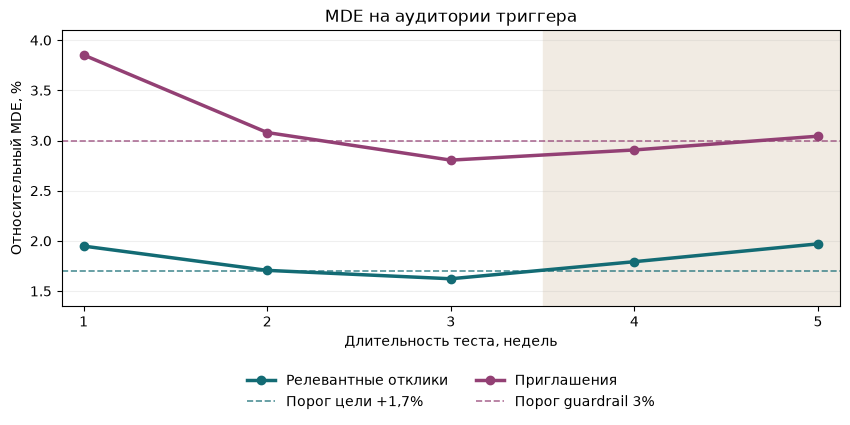

In [7]:
mde = results.pivot(index="weeks", columns="metric", values="mde_pct")
fig, ax = plt.subplots(figsize=(8.6, 4.5))
for metric, label, color, limit, limit_label in [
    (target, "Релевантные отклики", "#136b74", target_limit_pct, "Порог цели +1,7%"),
    (guardrail, "Приглашения", "#934074", guardrail_limit_pct, "Порог guardrail 3%"),
]:
    ax.plot(mde.index, mde[metric], marker="o", lw=2.5, color=color, label=label)
    ax.axhline(limit, ls="--", lw=1.2, color=color, alpha=0.75,
               label=limit_label)
ax.axvspan(3.5, 5.12, color="#f1ebe3", zorder=0)
ax.set(xlabel="Длительность теста, недель", ylabel="Относительный MDE, %",
       title="MDE на аудитории триггера", xticks=mde.index,
       xlim=(0.88, 5.12), ylim=(1.35, 4.1))
ax.grid(axis="y", alpha=0.2)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=2, frameon=False)
fig.tight_layout()
plt.show()


Минимальный MDE по обеим метрикам: на трех неделях. Число уникальных соискателей с откликом растет с 94868 за одну неделю до 197889 за три. До трех недель рост выборки перевешивает рост относительного разброса метрик, и обе кривые идут вниз.
В окнах на четыре и пять недель, выделенных на графике, в историческом периоде уже есть майские праздники. Четвертая неделя добавляет 10642 новых для выборки соискателя с откликом, пятая еще 7981. При этом с третьей по пятую неделю коэффициент вариации растет с 1,29 до 1,64 для релевантных откликов и с 2,51 до 2,85 для приглашений. Этот рост перевешивает прибавку к выборке, поэтому MDE обеих метрик повышается.

Только три недели укладываются в оба бизнес-порога, показанных пунктиром. MDE релевантных откликов составляет 1,623% (при пороге роста 1.7%), а MDE приглашений 2,805% при допустимой просадке 3%. За две недели оба MDE еще выше порогов. За четыре недели порог превышает MDE релевантных откликов, за пять недель MDE обеих метрик


## Задание 3. Выбор длительности эксперимента

Выбираем 3 недели, с 5 по 25 апреля 2027 года включительно. Это три полных недельных цикла до майских праздников и единственное окно, где оба MDE укладываются в бизнес-пороги.

В историческом аналоге за три недели было 197889 соискателей с откликом, около 98945 на группу при сплите 50/50. Если трафик и разброс будут сопоставимы с историей, мощность около 80% для каждой метрики соответствует росту релевантных откликов на 1,623% и снижению приглашений на 2,805%.


In [12]:
selected_weeks = 3

table = mde[[target, guardrail]].copy()
table["Оба порога достижимы"] = (
    (table[target] <= target_limit_pct) & (table[guardrail] <= guardrail_limit_pct)
).map({True: "Да", False: "Нет"})

week_labels = {
    1: "1 неделя",
    2: "2 недели",
    3: "3 недели",
    4: "4 недели",
    5: "5 недель",
}

table = (
    table.rename_axis("Длительность")
    .rename(index=week_labels)
    .rename(columns={
        target: "MDE релевантных откликов, порог роста +1,7%",
        guardrail: "MDE приглашений, порог просадки −3%",
    })
    .reset_index()
)

percent_columns = table.columns[1:3]

def format_percent(value):
    return f"{value:.3f}%"

def highlight_matching_row(row):
    style = "font-weight: bold" if row["Оба порога достижимы"] == "Да" else ""
    return [style] * len(row)

display(
    table.style
    .hide(axis="index")
    .format(format_percent, subset=percent_columns)
    .apply(highlight_matching_row, axis=1)
)

Длительность,"MDE релевантных откликов, порог роста +1,7%","MDE приглашений, порог просадки −3%",Оба порога достижимы
1 неделя,1.948%,3.852%,Нет
2 недели,1.706%,3.079%,Нет
3 недели,1.623%,2.805%,Да
4 недели,1.793%,2.906%,Нет
5 недель,1.970%,3.043%,Нет


## Задание 5. A/A-тесты на истории

### Подготовка пользовательской выборки

Для A/A берем ту же аудиторию, что и для трехнедельного MDE, с 6 по 26 апреля 2026 года. У каждого участника есть хотя бы один отклик за окно. Пользовательские суммы релевантных откликов включают нули.

In [9]:
aa_values = triggered_by_weeks[selected_weeks][target].to_numpy(dtype=float)

print(f"Соискателей с хотя бы одним откликом: {len(aa_values):,}")
print(f"Среднее число релевантных откликов: {aa_values.mean():.4f}")

Соискателей с хотя бы одним откликом: 197,889
Среднее число релевантных откликов: 4.2183


### Доля ложных срабатываний в 1000 разбиениях

В каждом запуске заново назначаем соискателей в A и B с равными вероятностями и сравниваем средние двусторонним t-тестом Уэлча. Реального воздействия нет, поэтому ожидаем около 5% запусков с p<0,05.

In [13]:
n_runs = 1000
rng = np.random.default_rng(42)
aa_runs = []

for run in range(1, n_runs + 1):
    in_b = rng.integers(0, 2, size=len(aa_values), dtype=np.int8).astype(bool)
    group_a = aa_values[~in_b]
    group_b = aa_values[in_b]

    test = ttest_ind(group_a, group_b, equal_var=False, alternative="two-sided")
    aa_runs.append({
        "run": run,
        "n_a": len(group_a),
        "n_b": len(group_b),
        "p_value": test.pvalue,
    })

aa_results = pd.DataFrame(aa_runs)
n_significant = int(aa_results["p_value"].lt(alpha).sum())
false_positive_rate = n_significant / n_runs
interval = binomtest(n_significant, n_runs).proportion_ci(confidence_level=0.95)

print(f"Запусков с p<{alpha}: {n_significant} из {n_runs}")
print(f"Доля ложных срабатываний: {false_positive_rate:.2%}")
print(f"95% доверительный интервал: [{interval.low:.2%}; {interval.high:.2%}]")

Запусков с p<0.05: 50 из 1000
Доля ложных срабатываний: 5.00%
95% доверительный интервал: [3.73%; 6.54%]


### Проверка SRM в первом разбиении

Критерий хи-квадрат сравнивает наблюдаемое число соискателей в A и B с ожидаемым при сплите 50/50. Используем порог p<0,001.

In [14]:
observed = aa_results.loc[0, ["n_a", "n_b"]].to_numpy(dtype=int)
expected = np.full(2, len(aa_values) / 2)
srm = chisquare(f_obs=observed, f_exp=expected)

display(pd.DataFrame({
    "Группа": ["A", "B"],
    "Фактически": observed,
    "Ожидается при 50/50": expected,
}))

print(f"χ²={srm.statistic:.4f}")
print(f"p-value SRM = {srm.pvalue:.4f}")
print("Обнаружен SRM" if srm.pvalue < 0.001 else "SRM не обнаружен")

,Группа,Фактически,Ожидается при 50/50
0,A,99085,98944.5
1,B,98804,98944.5


χ²=0.3990
p-value SRM = 0.5276
SRM не обнаружен


В 50 из 1000 A/A запусков получили p<0,05. Доля ложных срабатываний составила 5%, а её 95% доверительный интервал [3,73%; 6,54%] включает ожидаемые 5%.

В первом разбиении в A попали 99085 соискателей, а в B 98804, при ожидаемых 98944,5 в каждой группе. Значение p(SRM)=0,5276 выше порога 0,001. Признаков перекоса численности в этом разбиении не обнаружено.
